In [1]:
!pip install -q pandas sqlalchemy psycopg2-binary openpyxl

In [2]:
import pandas as pd
import psycopg2
from sqlalchemy import create_engine
from urllib.parse import quote_plus
from datetime import datetime

print("Library berhasil diimpor!")

Library berhasil diimpor!


In [4]:
from google.colab import userdata

SOURCE_URL = userdata.get("SOURCE_URL")
DW_URL = userdata.get("DW_URL")

print("SOURCE_URL tersedia:", bool(SOURCE_URL))
print("DW_URL tersedia:", bool(DW_URL))

print("Awalan SOURCE:", SOURCE_URL[:13] if SOURCE_URL else "KOSONG")
print("Awalan DW:", DW_URL[:13] if DW_URL else "KOSONG")

SOURCE_URL tersedia: True
DW_URL tersedia: True
Awalan SOURCE: Connection st
Awalan DW: Connection st


In [5]:
from google.colab import userdata

SOURCE_URL = userdata.get("SOURCE_URL")
DW_URL = userdata.get("DW_URL")

print("SOURCE tersedia:", bool(SOURCE_URL))
print("DW tersedia:", bool(DW_URL))

print("SOURCE prefix:", SOURCE_URL[:13] if SOURCE_URL else "KOSONG")
print("DW prefix:", DW_URL[:13] if DW_URL else "KOSONG")

SOURCE tersedia: True
DW tersedia: True
SOURCE prefix: postgresql://
DW prefix: postgresql://


In [6]:
# Menguji koneksi database sumber
try:
    conn_source = psycopg2.connect(SOURCE_URL)
    print("DB_PUSAT: Koneksi berhasil!")
    conn_source.close()
except Exception as e:
    print("DB_PUSAT: Koneksi gagal!")
    print("Error:", str(e)[:300])

# Menguji koneksi Data Warehouse
try:
    conn_dw = psycopg2.connect(DW_URL)
    print("DW_HARGA_BERAS_SUMUT: Koneksi berhasil!")
    conn_dw.close()
except Exception as e:
    print("DW_HARGA_BERAS_SUMUT: Koneksi gagal!")
    print("Error:", str(e)[:300])

DB_PUSAT: Koneksi berhasil!
DW_HARGA_BERAS_SUMUT: Koneksi berhasil!


In [7]:
# Menghubungkan kembali ke database sumber
conn_source = psycopg2.connect(SOURCE_URL)

# Mengambil data harga beras dari DB_PUSAT
df = pd.read_sql_query("""
    SELECT
        kode_harga,
        kualitas_beras,
        tanggal,
        harga,
        wilayah_sumber,
        updated_at
    FROM public.harga_beras_pusat;
""", conn_source)

# Menutup koneksi
conn_source.close()

# Menampilkan hasil pengambilan data
print("Data berhasil diambil!")
print("Jumlah baris:", len(df))

display(df.head())

/tmp/ipykernel_979/3517587682.py:5: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query("""


Data berhasil diambil!
Jumlah baris: 231


,kode_harga,kualitas_beras,tanggal,harga,wilayah_sumber,updated_at
0,PSP-010,Beras,2026-10-01,14200.0,PADANG SIDEMPUAN,2026-11-16 15:17:35.666265+00:00
1,PSI-001,Beras,2026-01-01,13250.0,PEMATANG SIANTAR,2026-11-16 15:19:13.369978+00:00
2,PSI-002,Beras,2026-02-02,13250.0,PEMATANG SIANTAR,2026-11-16 15:19:13.369978+00:00
3,PSI-003,Beras,2026-03-02,13250.0,PEMATANG SIANTAR,2026-11-16 15:19:13.369978+00:00
4,PSI-004,Beras,2026-04-01,13250.0,PEMATANG SIANTAR,2026-11-16 15:19:13.369978+00:00


In [8]:
# Membuat salinan data hasil Extract
df_clean = df.copy()

# 1. Membersihkan spasi pada kolom teks
text_columns = ["kode_harga", "kualitas_beras", "wilayah_sumber"]

for col in text_columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()

# 2. Mengubah format tanggal
df_clean["tanggal"] = pd.to_datetime(
    df_clean["tanggal"], errors="coerce"
)

# 3. Mengubah harga menjadi numerik
df_clean["harga"] = pd.to_numeric(
    df_clean["harga"], errors="coerce"
)

# 4. Mengubah updated_at menjadi format datetime
df_clean["updated_at"] = pd.to_datetime(
    df_clean["updated_at"], errors="coerce"
)

# 5. Memeriksa data kosong
print("TRANSFORMASI SELESAI")
print("Jumlah baris:", len(df_clean))

print("\nJumlah data kosong:")
print(df_clean.isnull().sum())

print("\nJumlah data duplikat:")
print(df_clean.duplicated().sum())

display(df_clean.head())

TRANSFORMASI SELESAI
Jumlah baris: 231

Jumlah data kosong:
kode_harga         0
kualitas_beras     0
tanggal            0
harga             30
wilayah_sumber     0
updated_at         0
dtype: int64

Jumlah data duplikat:
0


,kode_harga,kualitas_beras,tanggal,harga,wilayah_sumber,updated_at
0,PSP-010,Beras,2026-10-01,14200.0,PADANG SIDEMPUAN,2026-11-16 15:17:35.666265+00:00
1,PSI-001,Beras,2026-01-01,13250.0,PEMATANG SIANTAR,2026-11-16 15:19:13.369978+00:00
2,PSI-002,Beras,2026-02-02,13250.0,PEMATANG SIANTAR,2026-11-16 15:19:13.369978+00:00
3,PSI-003,Beras,2026-03-02,13250.0,PEMATANG SIANTAR,2026-11-16 15:19:13.369978+00:00
4,PSI-004,Beras,2026-04-01,13250.0,PEMATANG SIANTAR,2026-11-16 15:19:13.369978+00:00


In [9]:
conn_source = psycopg2.connect(SOURCE_URL)

df = pd.read_sql_query("""
SELECT
    kode_harga,
    kualitas_beras,
    tanggal,
    harga,
    wilayah_sumber,
    updated_at
FROM public.harga_beras_pusat
ORDER BY tanggal, wilayah_sumber, kualitas_beras;
""", conn_source)

conn_source.close()

print("Total data:", len(df))
print("Harga kosong:", df["harga"].isna().sum())
print("Harga terisi:", df["harga"].notna().sum())

display(df.head())

/tmp/ipykernel_979/2619741938.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query("""


Total data: 231
Harga kosong: 0
Harga terisi: 231


,kode_harga,kualitas_beras,tanggal,harga,wilayah_sumber,updated_at
0,GNS-001,Beras,2026-01-01,13850.0,GUNUNG SITOLI,2026-11-16 15:20:15.474601+00:00
1,GNS-012,Beras Kualitas Bawah I,2026-01-01,13900.0,GUNUNG SITOLI,2026-11-16 15:20:15.474601+00:00
2,GNS-023,Beras Kualitas Bawah II,2026-01-01,14500.0,GUNUNG SITOLI,2026-11-16 15:20:15.474601+00:00
3,GNS-034,Beras Kualitas Medium I,2026-01-01,14500.0,GUNUNG SITOLI,2026-11-16 15:20:15.474601+00:00
4,GNS-045,Beras Kualitas Medium II,2026-01-01,13400.0,GUNUNG SITOLI,2026-11-16 15:20:15.474601+00:00


In [10]:
# Memastikan data siap diproses
assert len(df) == 231, "Jumlah data bukan 231!"
assert df["harga"].notna().all(), "Masih ada harga kosong!"

# 1. Membuat key wilayah
wilayah_values = sorted(df["wilayah_sumber"].dropna().unique())
wilayah_map = {
    nama: i + 1
    for i, nama in enumerate(wilayah_values)
}

# 2. Membuat key kualitas beras
kualitas_values = sorted(df["kualitas_beras"].dropna().unique())
kualitas_map = {
    nama: i + 1
    for i, nama in enumerate(kualitas_values)
}

# 3. Membuat key tanggal
tanggal_values = sorted(df["tanggal"].dropna().unique())
tanggal_map = {
    tanggal: int(tanggal.strftime("%Y%m%d"))
    for tanggal in tanggal_values
}

print("KEY DIMENSI BERHASIL DIBUAT")
print("Jumlah wilayah:", len(wilayah_map))
print("Jumlah kualitas:", len(kualitas_map))
print("Jumlah tanggal:", len(tanggal_map))

print("\nKey wilayah:")
print(wilayah_map)

print("\nKey kualitas:")
print(kualitas_map)

KEY DIMENSI BERHASIL DIBUAT
Jumlah wilayah: 3
Jumlah kualitas: 7
Jumlah tanggal: 11

Key wilayah:
{'GUNUNG SITOLI': 1, 'PADANG SIDEMPUAN': 2, 'PEMATANG SIANTAR': 3}

Key kualitas:
{'Beras': 1, 'Beras Kualitas Bawah I': 2, 'Beras Kualitas Bawah II': 3, 'Beras Kualitas Medium I': 4, 'Beras Kualitas Medium II': 5, 'Beras Kualitas Super I': 6, 'Beras Kualitas Super II': 7}


In [11]:
nama_bulan = {
    1: "Januari",
    2: "Februari",
    3: "Maret",
    4: "April",
    5: "Mei",
    6: "Juni",
    7: "Juli",
    8: "Agustus",
    9: "September",
    10: "Oktober",
    11: "November",
    12: "Desember"
}

conn = psycopg2.connect(DW_URL)

try:
    with conn:
        with conn.cursor() as cur:

            # DIMENSI WILAYAH
            for nama, key in wilayah_map.items():
                cur.execute("""
                    INSERT INTO dw.dim_wilayah
                    (wilayah_key, nama_wilayah)
                    VALUES (%s, %s)
                    ON CONFLICT (wilayah_key)
                    DO UPDATE SET
                    nama_wilayah = EXCLUDED.nama_wilayah
                """, (key, nama))

            # DIMENSI KUALITAS BERAS
            for nama, key in kualitas_map.items():
                cur.execute("""
                    INSERT INTO dw.dim_kualitas_beras
                    (kualitas_key, kualitas_beras)
                    VALUES (%s, %s)
                    ON CONFLICT (kualitas_key)
                    DO UPDATE SET
                    kualitas_beras = EXCLUDED.kualitas_beras
                """, (key, nama))

            # DIMENSI TANGGAL
            for tanggal, key in tanggal_map.items():
                cur.execute("""
                    INSERT INTO dw.dim_tanggal
                    (tanggal_key, tanggal, hari, bulan,
                     nama_bulan, kuartal, tahun)
                    VALUES (%s, %s, %s, %s, %s, %s, %s)
                    ON CONFLICT (tanggal_key)
                    DO UPDATE SET
                    tanggal = EXCLUDED.tanggal,
                    hari = EXCLUDED.hari,
                    bulan = EXCLUDED.bulan,
                    nama_bulan = EXCLUDED.nama_bulan,
                    kuartal = EXCLUDED.kuartal,
                    tahun = EXCLUDED.tahun
                """, (
                    key,
                    tanggal,
                    tanggal.day,
                    tanggal.month,
                    nama_bulan[tanggal.month],
                    (tanggal.month - 1) // 3 + 1,
                    tanggal.year
                ))

    print("Dimensi berhasil dimuat!")

finally:
    conn.close()

Dimensi berhasil dimuat!


In [12]:
conn = psycopg2.connect(DW_URL)

for table in [
    "dim_wilayah",
    "dim_kualitas_beras",
    "dim_tanggal"
]:
    result = pd.read_sql_query(
        f"SELECT COUNT(*) AS jumlah FROM dw.{table}",
        conn
    )
    print(table, ":", result.iloc[0]["jumlah"])

conn.close()

/tmp/ipykernel_979/3381531574.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql_query(


dim_wilayah : 3
dim_kualitas_beras : 7
dim_tanggal : 11


In [13]:
# Memastikan data dan key dimensi sudah tersedia
assert len(df) == 231, "Jumlah data harus 231!"
assert df["harga"].notna().all(), "Masih ada harga kosong!"

assert len(wilayah_map) == 3
assert len(kualitas_map) == 7
assert len(tanggal_map) == 11

from psycopg2.extras import execute_values

# Membentuk data untuk tabel fakta
fact_rows = []

for row in df.itertuples(index=False):
    fact_rows.append((
        row.kode_harga,
        wilayah_map[row.wilayah_sumber],
        kualitas_map[row.kualitas_beras],
        tanggal_map[row.tanggal],
        float(row.harga),
        row.updated_at
    ))

print("Persiapan data fakta berhasil!")
print("Jumlah baris siap dimuat:", len(fact_rows))

Persiapan data fakta berhasil!
Jumlah baris siap dimuat: 231


In [14]:
conn = psycopg2.connect(DW_URL)

try:
    with conn:
        with conn.cursor() as cur:
            execute_values(
                cur,
                """
                INSERT INTO dw.fact_harga_beras
                (
                    kode_harga,
                    wilayah_key,
                    kualitas_key,
                    tanggal_key,
                    harga,
                    updated_at
                )
                VALUES %s

                ON CONFLICT (
                    wilayah_key,
                    kualitas_key,
                    tanggal_key
                )
                DO UPDATE SET
                    kode_harga = EXCLUDED.kode_harga,
                    harga = EXCLUDED.harga,
                    updated_at = EXCLUDED.updated_at,
                    loaded_at = CURRENT_TIMESTAMP
                """,
                fact_rows
            )

    print("LOAD TABEL FAKTA BERHASIL!")
    print("Jumlah data diproses:", len(fact_rows))

finally:
    conn.close()

LOAD TABEL FAKTA BERHASIL!
Jumlah data diproses: 231


In [15]:
conn = psycopg2.connect(DW_URL)

hasil = pd.read_sql_query("""
    SELECT
        COUNT(*) AS total_data,
        COUNT(*) FILTER (
            WHERE harga IS NULL
        ) AS harga_kosong,
        COUNT(*) FILTER (
            WHERE harga IS NOT NULL
        ) AS harga_terisi
    FROM dw.fact_harga_beras;
""", conn)

conn.close()

display(hasil)

/tmp/ipykernel_979/1960730646.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  hasil = pd.read_sql_query("""


,total_data,harga_kosong,harga_terisi
0,231,0,231


In [16]:
# Memeriksa database sumber
conn = psycopg2.connect(SOURCE_URL)

source_check = pd.read_sql_query("""
SELECT
    COUNT(*) AS total_data,
    COUNT(*) FILTER (WHERE harga IS NULL) AS harga_kosong,
    COUNT(*) FILTER (WHERE harga IS NOT NULL) AS harga_terisi
FROM public.harga_beras_pusat;
""", conn)

conn.close()

# Memeriksa Data Warehouse
conn = psycopg2.connect(DW_URL)

dw_check = pd.read_sql_query("""
SELECT
    COUNT(*) AS total_data,
    COUNT(*) FILTER (WHERE harga IS NULL) AS harga_kosong,
    COUNT(*) FILTER (WHERE harga IS NOT NULL) AS harga_terisi
FROM dw.fact_harga_beras;
""", conn)

conn.close()

print("HASIL DB_PUSAT")
display(source_check)

print("HASIL DATA WAREHOUSE")
display(dw_check)

/tmp/ipykernel_979/1843417611.py:4: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  source_check = pd.read_sql_query("""
/tmp/ipykernel_979/1843417611.py:17: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  dw_check = pd.read_sql_query("""


HASIL DB_PUSAT


,total_data,harga_kosong,harga_terisi
0,231,0,231


HASIL DATA WAREHOUSE


,total_data,harga_kosong,harga_terisi
0,231,0,231


In [17]:
# Mengambil data dari DB_PUSAT
conn = psycopg2.connect(SOURCE_URL)

src = pd.read_sql_query("""
SELECT
    kode_harga,
    kualitas_beras,
    tanggal,
    harga,
    wilayah_sumber
FROM public.harga_beras_pusat;
""", conn)

conn.close()

# Mengambil data dari Data Warehouse
conn = psycopg2.connect(DW_URL)

wh = pd.read_sql_query("""
SELECT
    f.kode_harga,
    q.kualitas_beras,
    t.tanggal,
    f.harga,
    w.nama_wilayah AS wilayah_sumber
FROM dw.fact_harga_beras f
JOIN dw.dim_wilayah w
    ON f.wilayah_key = w.wilayah_key
JOIN dw.dim_kualitas_beras q
    ON f.kualitas_key = q.kualitas_key
JOIN dw.dim_tanggal t
    ON f.tanggal_key = t.tanggal_key;
""", conn)

conn.close()

# Menyamakan format tanggal
src["tanggal"] = pd.to_datetime(src["tanggal"])
wh["tanggal"] = pd.to_datetime(wh["tanggal"])

# Menggabungkan data sumber dan warehouse
keys = [
    "kode_harga",
    "kualitas_beras",
    "tanggal",
    "wilayah_sumber"
]

m = src.merge(
    wh,
    on=keys,
    how="outer",
    suffixes=("_src", "_dw"),
    indicator=True,
    validate="one_to_one"
)

# Memeriksa data yang cocok
both = m[m["_merge"] == "both"].copy()

# Memeriksa perbedaan harga
diff = both[
    (both["harga_src"] - both["harga_dw"]).abs() > 0.01
]

print("HASIL VALIDASI DATA")
print("Pasangan data:", len(both))
print("Harga berbeda:", len(diff))
print("Tidak berpasangan:", (m["_merge"] != "both").sum())

print("\nData yang berbeda:")
display(diff)

/tmp/ipykernel_979/4246746726.py:4: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  src = pd.read_sql_query("""
/tmp/ipykernel_979/4246746726.py:19: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  wh = pd.read_sql_query("""


HASIL VALIDASI DATA
Pasangan data: 231
Harga berbeda: 0
Tidak berpasangan: 0

Data yang berbeda:


,kode_harga,kualitas_beras,tanggal,harga_src,wilayah_sumber,harga_dw,_merge


In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import psycopg2

# Mengambil data dari Data Warehouse
conn = psycopg2.connect(DW_URL)

query_tren = """
SELECT
    t.tahun,
    t.bulan,
    t.nama_bulan,
    w.nama_wilayah,
    ROUND(AVG(f.harga), 2) AS rata_rata_harga
FROM dw.fact_harga_beras f
JOIN dw.dim_tanggal t
    ON f.tanggal_key = t.tanggal_key
JOIN dw.dim_wilayah w
    ON f.wilayah_key = w.wilayah_key
GROUP BY
    t.tahun,
    t.bulan,
    t.nama_bulan,
    w.nama_wilayah
ORDER BY
    t.tahun,
    t.bulan,
    w.nama_wilayah;
"""

df_tren = pd.read_sql_query(query_tren, conn)
conn.close()

display(df_tren.head())

/tmp/ipykernel_979/3966580873.py:31: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_tren = pd.read_sql_query(query_tren, conn)


,tahun,bulan,nama_bulan,nama_wilayah,rata_rata_harga
0,2026,1,Januari,GUNUNG SITOLI,13850.00
1,2026,1,Januari,PADANG SIDEMPUAN,14207.14
2,2026,1,Januari,PEMATANG SIANTAR,13264.29
3,2026,2,Februari,GUNUNG SITOLI,13850.00
4,2026,2,Februari,PADANG SIDEMPUAN,14207.14


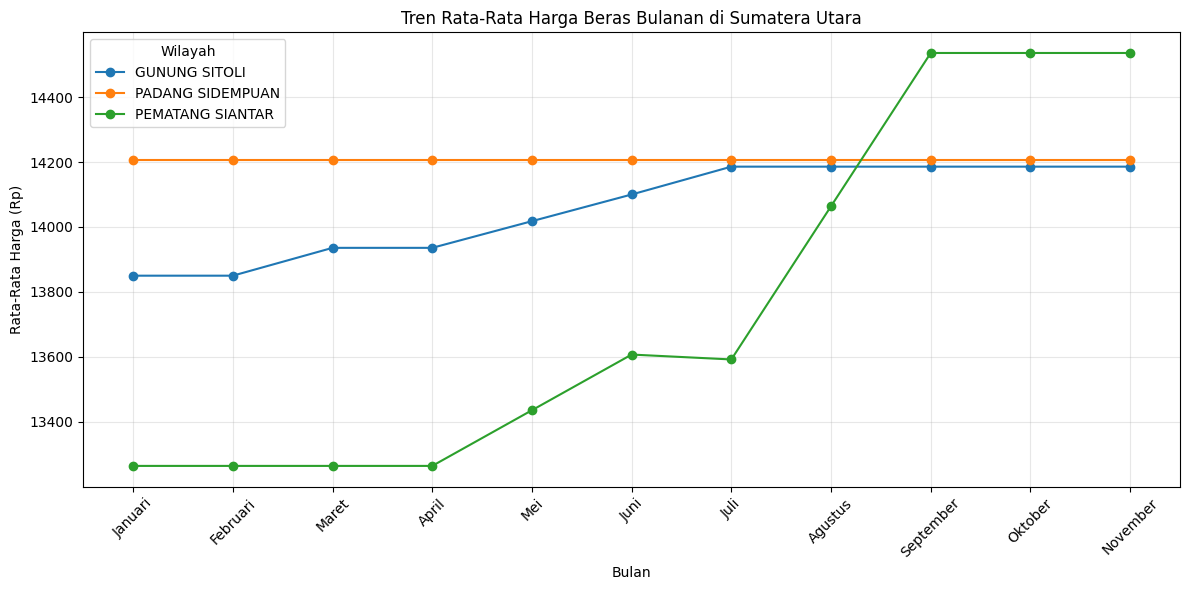

In [19]:
plt.figure(figsize=(12, 6))

for wilayah in df_tren["nama_wilayah"].unique():
    data_wilayah = df_tren[
        df_tren["nama_wilayah"] == wilayah
    ]

    plt.plot(
        data_wilayah["nama_bulan"],
        data_wilayah["rata_rata_harga"],
        marker="o",
        label=wilayah
    )

plt.title("Tren Rata-Rata Harga Beras Bulanan di Sumatera Utara")
plt.xlabel("Bulan")
plt.ylabel("Rata-Rata Harga (Rp)")
plt.legend(title="Wilayah")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "tren_harga_bulanan.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
from google.colab import files

files.download("tren_harga_bulanan.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
conn = psycopg2.connect(DW_URL)

query_wilayah = """
SELECT
    w.nama_wilayah,
    ROUND(AVG(f.harga), 2) AS rata_rata_harga
FROM dw.fact_harga_beras f
JOIN dw.dim_wilayah w
    ON f.wilayah_key = w.wilayah_key
GROUP BY w.nama_wilayah
ORDER BY rata_rata_harga DESC;
"""

df_wilayah = pd.read_sql_query(query_wilayah, conn)
conn.close()

display(df_wilayah)

/tmp/ipykernel_979/4153222105.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_wilayah = pd.read_sql_query(query_wilayah, conn)


,nama_wilayah,rata_rata_harga
0,PADANG SIDEMPUAN,14207.14
1,GUNUNG SITOLI,14056.17
2,PEMATANG SIANTAR,13760.28


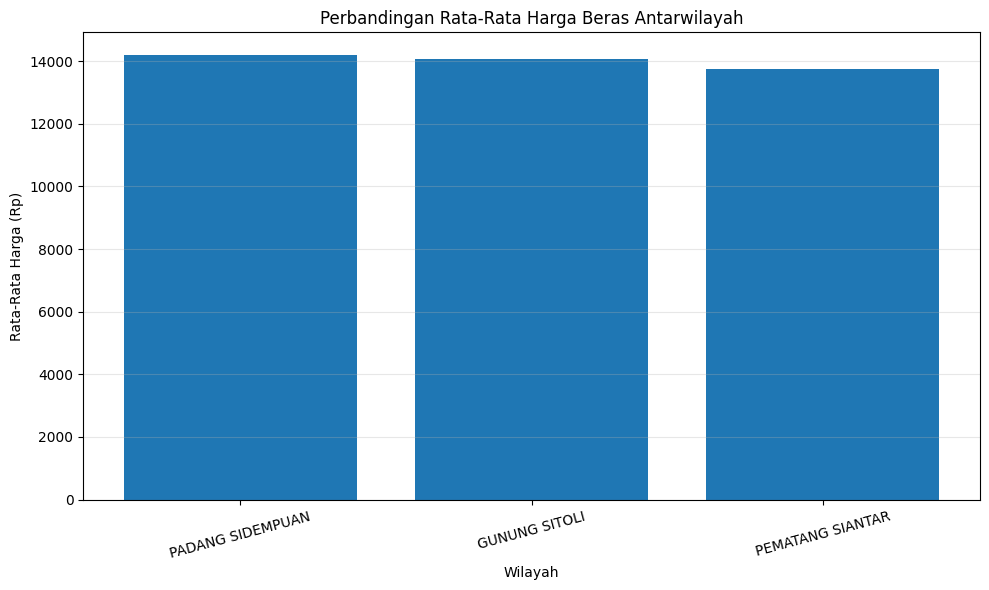

In [21]:
plt.figure(figsize=(10, 6))

plt.bar(
    df_wilayah["nama_wilayah"],
    df_wilayah["rata_rata_harga"]
)

plt.title("Perbandingan Rata-Rata Harga Beras Antarwilayah")
plt.xlabel("Wilayah")
plt.ylabel("Rata-Rata Harga (Rp)")
plt.xticks(rotation=15)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "perbandingan_harga_antarwilayah.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [22]:
from google.colab import files

files.download("perbandingan_harga_antarwilayah.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>